# 02 — Prétraitement, découpage et sélection des variables

**Objectif** : passer des données brutes à des jeux `train` et `test` propres, et choisir, par des analyses lisibles, les variables les plus intéressantes pour prédire l'étiquette DPE et la consommation.

**Ordre de travail (il évite toute fuite de données)**
1. Diagnostic des quasi-doublons, qui justifie le découpage par adresse.
2. Nettoyage **ligne par ligne** (lignes inutilisables, valeurs impossibles, regroupement de libellés) : cela n'apprend rien des données, donc cela peut précéder le découpage.
3. **Découpage train/test**, groupé par adresse et stratifié sur l'étiquette.
4. Comparaison simple de train et de test.
5. **Sélection de variables sur le train uniquement** : manquants, variables quasi constantes, corrélations, lien avec la consommation, importance dans une forêt aléatoire.
6. Validation du préprocesseur.
7. Sauvegarde.

**Règle** : le test ne sert jamais à décider quoi que ce soit. Il est seulement comparé au train (section 4), puis utilisé pour l'évaluation finale dans les notebooks suivants.

## 0. Préparation et décisions

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import f1_score, mean_absolute_error
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline

RACINE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RACINE))

from src.utilis import config
from src.data import transformateurs as tf

pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
plt.rcParams["figure.figsize"] = (9, 4.5)

DOSSIER_FIG = config.RACINE / "reports" / "figures"
ETIQ, CONSO = config.CIBLE_CLASSIFICATION, config.CIBLE_REGRESSION
ORDRE = config.ORDRE_ETIQUETTES
GRAINE = config.GRAINE_ALEATOIRE


def sauver(fig, nom):
    DOSSIER_FIG.mkdir(parents=True, exist_ok=True)
    fig.savefig(DOSSIER_FIG / f"{nom}.png", dpi=150, bbox_inches="tight")

In [2]:

# DÉCISIONS DE CE NOTEBOOK : tout ce qu'on peut vouloir changer est ici.
# Reglages des seuils 
DEDOUBLONNER_COPIES_EXACTES = True   # True : ne garder qu'une ligne parmi les copies exactes
SEUIL_CONSO_ABERRANTE = 1000          # kWhEP/m²/an : au-delà, la ligne est marquée (non supprimée)
SEUIL_STRATE_RARE = 20                # strates étiquette x jeu plus petites : regroupées par étiquette

SEUIL_MANQUANTS = 0.50                # au-delà : variable écartée
SEUIL_PART_DOMINANTE = 0.99           # au-delà : variable quasi constante, écartée
SEUIL_CORRELATION = 0.90              # |Spearman| entre deux numériques : l'une est redondante
PART_IMPORTANCE_CUMULEE = 0.95        # on garde les variables qui portent 95 % de l'importance

# Libellés détaillés remplacés par leur famille (créée en section 2).
REMPLACEES = {
    "type_ventilation": "famille_ventilation",
    "type_energie_principale_chauffage": "famille_energie_chauffage",
    "type_energie_principale_ecs": "famille_energie_ecs",
}

# Retraits décidés après analyse : {variable: raison}. Cette raison ira dans le rapport.
RETIRER_MANUELLEMENT = {
}
GARDER_MANUELLEMENT = []              # variables conservées malgré les règles (à justifier)

## 1. Chargement et diagnostic des quasi-doublons

In [3]:
df = pd.concat(
    [pd.read_csv(config.DATA_BRUT / f"dpe_{nom}.csv", low_memory=False) for nom in config.DATASETS],
    ignore_index=True,
)
for col in ["date_reception_dpe", "date_etablissement_dpe", "date_derniere_modification_dpe"]:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors="coerce")
print(f"{len(df):,} lignes brutes")
print(df["source_jeu"].value_counts().to_string())

59,702 lignes brutes
source_jeu
existant    54399
neuf         5303


Un même immeuble peut produire plusieurs DPE quasi identiques (par exemple des appartements « générés à partir des données DPE immeuble »). Ces lignes ne sont pas des erreurs, mais si elles se retrouvent à la fois dans le train et dans le test, le score du test est trop optimiste. On mesure leur poids, par méthode de calcul.

In [4]:
# On définit une clé d’identification approximative d’un logement cle_logement qui regroupe l’adresse et la surface habitable
''' 
 Deux DPE qui partagent la même adresse et la même surface ont 
 de bonnes chances de concerner le même logement ou des logements très semblables.

'''
cle_logement = ["adresse_ban", "surface_habitable_logement"]
# On ne garde que les lignes avec adresse + surface renseignées, pour pouvoir identifier les doublons.
base = df.dropna(subset=cle_logement).copy()

# On regroupe les lignes qui ont la même adresse et la même surface, puis on écrit pour chaque ligne la taille de son groupe.
base["taille_groupe"] = base.groupby(cle_logement)["numero_dpe"].transform("size")

base["dans_un_groupe"] = base["taille_groupe"] > 1 # Vrai si la ligne a au moins un semblable (quasi doublons) à la même adresse et avec la même surface.

colonnes_copie = ["adresse_ban"] + [c for c in config.VARIABLES_CANDIDATES if c in df.columns] + [ETIQ, CONSO]
# meme addresse, meme surface, meme variables candidates et meme cible => copie exacte
base["copie_exacte"] = base.duplicated(subset=colonnes_copie, keep=False)

print(f"Lignes dans un groupe adresse + surface : {base['dans_un_groupe'].mean():.1%}")
print(f"Copies exactes (mêmes variables et même cible) : {base['copie_exacte'].mean():.1%}")
(base.groupby("methode_application_dpe")[["dans_un_groupe", "copie_exacte"]].mean()
     .join(base.groupby("methode_application_dpe").size().rename("lignes"))
     .sort_values("lignes", ascending=False))

Lignes dans un groupe adresse + surface : 40.9%
Copies exactes (mêmes variables et même cible) : 24.0%


,dans_un_groupe,copie_exacte,lignes
methode_application_dpe,,,
dpe appartement individuel,0.269,0.089,30919
dpe maison individuelle,0.211,0.112,13118
dpe appartement généré à partir des données DPE immeuble,0.960,0.785,10052
dpe issu d'une étude thermique réglementaire RT2012 bâtiment : appartement,0.870,0.527,3206
dpe issu d'une étude thermique réglementaire RT2012 bâtiment : maison individuelle,0.344,0.207,812
dpe issu d'une étude energie environement réglementaire RE2020 bâtiment : maison individuelle,0.056,0.042,143
dpe issu d'une étude thermique réglementaire RT2012 bâtiment : immeuble,0.579,0.263,76
dpe issu d'une étude energie environement réglementaire RE2020 bâtiment : appartement,0.880,0.160,25


In [5]:
# Information sur les groupes de DPE qui partagent la même adresse et la même surface.
groupes = base.groupby(cle_logement).agg(
    taille=("numero_dpe", "size"), nb_etiquettes=(ETIQ, "nunique"), nb_dates=("date_reception_dpe", "nunique"),
)
groupes = groupes[groupes["taille"] > 1]
print(f"{len(groupes):,} groupes de plusieurs DPE")
print(f"Part des groupes avec une seule étiquette : {(groupes['nb_etiquettes'] == 1).mean():.1%}")
print(f"Part des groupes reçus le même jour : {(groupes['nb_dates'] == 1).mean():.1%}")
print(groupes["taille"].describe(percentiles=[0.5, 0.9, 0.99]).to_string())

4,893 groupes de plusieurs DPE
Part des groupes avec une seule étiquette : 76.4%
Part des groupes reçus le même jour : 54.5%
count   4,893.000
mean        4.883
std        11.015
min         2.000
50%         2.000
90%         8.000
99%        44.000
max       284.000


In [6]:
# Affichage des 10 premières copies exactes générées à partir des données DPE immeuble.
CE = base.loc[
    base["copie_exacte"]
    & base["methode_application_dpe"].str.contains(
        "généré à partir des données DPE immeuble",
        case=False,
        na=False
    )
]

CE[colonnes_copie].head(10)

,adresse_ban,surface_habitable_logement,hauteur_sous_plafond,annee_construction,nombre_niveau_logement,numero_etage_appartement,nombre_niveau_immeuble,nombre_appartement,surface_habitable_immeuble,volume_stockage_generateur_n1_ecs_n1,surface_chauffee_installation_chauffage_n1,type_batiment,periode_construction,qualite_isolation_murs,qualite_isolation_menuiseries,qualite_isolation_plancher_bas,qualite_isolation_enveloppe,type_energie_principale_chauffage,type_installation_chauffage,type_energie_principale_ecs,type_ventilation,zone_climatique,classe_altitude,classe_inertie_batiment,logement_traversant,type_generateur_chauffage_principal,type_emetteur_installation_chauffage_n1,type_generateur_n1_installation_n1,type_installation_ecs,type_generateur_chauffage_principal_ecs,type_generateur_n1_ecs_n1,typologie_logement,position_logement_dans_immeuble,isolation_toiture,inertie_lourde,type_generateur_froid,protection_solaire_exterieure,presence_brasseur_air,presence_production_pv,type_installation_solaire_n1,etiquette_dpe,conso_5_usages_par_m2_ep
3034,Residence Bertrand Porette 20250 Corte,26.000,2.500,"1,992.000",1.000,NaN,7.000,197.000,"5,186.000","4,000.000",26.000,appartement,1989-2000,moyenne,moyenne,insuffisante,insuffisante,Réseau de Chauffage urbain,mixte (collectif-individuel),Réseau de Chauffage urbain,VMC SF Auto réglable de 1982 à 2000,H3,inférieur à 400m,Moyenne,NaN,NaN,Radiateur bitube avec robinet thermostatique s...,réseau de chaleur non répertorié ou inconnu,individuel,NaN,réseau de chaleur non répertorié ou inconnu,T1,étage intermédiaire,NaN,NaN,NaN,NaN,NaN,0.000,Non affecté,C,142.500
3048,Residence Bertrand Porette 20250 Corte,26.000,2.500,"1,992.000",1.000,NaN,7.000,197.000,"5,186.000","4,000.000",26.000,appartement,1989-2000,moyenne,moyenne,insuffisante,insuffisante,Réseau de Chauffage urbain,mixte (collectif-individuel),Réseau de Chauffage urbain,VMC SF Auto réglable de 1982 à 2000,H3,inférieur à 400m,Moyenne,NaN,NaN,Radiateur bitube avec robinet thermostatique s...,réseau de chaleur non répertorié ou inconnu,individuel,NaN,réseau de chaleur non répertorié ou inconnu,T1,étage intermédiaire,NaN,NaN,NaN,NaN,NaN,0.000,Non affecté,C,142.500
3069,Residence Bertrand Porette 20250 Corte,26.000,2.500,"1,992.000",1.000,NaN,7.000,197.000,"5,186.000","4,000.000",26.000,appartement,1989-2000,moyenne,moyenne,insuffisante,insuffisante,Réseau de Chauffage urbain,mixte (collectif-individuel),Réseau de Chauffage urbain,VMC SF Auto réglable de 1982 à 2000,H3,inférieur à 400m,Moyenne,NaN,NaN,Radiateur bitube avec robinet thermostatique s...,réseau de chaleur non répertorié ou inconnu,individuel,NaN,réseau de chaleur non répertorié ou inconnu,T1,étage intermédiaire,NaN,NaN,NaN,NaN,NaN,0.000,Non affecté,C,142.500
3070,Residence Bertrand Porette 20250 Corte,26.000,2.500,"1,992.000",1.000,NaN,7.000,197.000,"5,186.000","4,000.000",26.000,appartement,1989-2000,moyenne,moyenne,insuffisante,insuffisante,Réseau de Chauffage urbain,mixte (collectif-individuel),Réseau de Chauffage urbain,VMC SF Auto réglable de 1982 à 2000,H3,inférieur à 400m,Moyenne,NaN,NaN,Radiateur bitube avec robinet thermostatique s...,réseau de chaleur non répertorié ou inconnu,individuel,NaN,réseau de chaleur non répertorié ou inconnu,T1,étage intermédiaire,NaN,NaN,NaN,NaN,NaN,0.000,Non affecté,C,142.500
3098,Residence Bertrand Porette 20250 Corte,26.000,2.500,"1,992.000",1.000,NaN,7.000,197.000,"5,186.000","4,000.000",26.000,appartement,1989-2000,moyenne,moyenne,insuffisante,insuffisante,Réseau de Chauffage urbain,mixte (collectif-individuel),Réseau de Chauffage urbain,VMC SF Auto réglable de 1982 à 2000,H3,inférieur à 400m,Moyenne,NaN,NaN,Radiateur bitube avec robinet thermostatique s...,réseau de chaleur non répertorié ou inconnu,individuel,NaN,réseau de chaleur non répertorié ou inconnu,T1,étage intermédiaire,NaN,NaN,NaN,NaN,NaN,0.000,Non affecté,C,142.500
3099,Residence Bertrand Porette 20250 Corte,26.000,2.500,"1,992.000",1.000,NaN,7.000,197.000,"5,186.000","4,00

**Décision** : on conserve par défaut toutes les lignes, car plusieurs logements différents peuvent réellement avoir les mêmes caractéristiques et les retirer changerait la population étudiée. Le risque de fuite est traité par le **découpage groupé par adresse**. Si les copies exactes pèsent trop, on passe `DEDOUBLONNER_COPIES_EXACTES` à `True` et comparer.

Aussi des observation identiques sur plusieurs sur nos variables n'est pas nécessairement un doublon réel dans la réalité.

## 2. Nettoyage ligne par ligne
Ces opérations ne regardent que la ligne elle-même : elles peuvent se faire avant le découpage sans fuite de données.

In [7]:
journal = [("lignes brutes", len(df), 0)]

# On retire les lignes sans cible (étiquette ou consommation) 
sans_cible = df[ETIQ].isna() | df[CONSO].isna()


n = len(df)
# 
df = df.loc[~sans_cible].copy()
journal.append(("sans étiquette ou sans consommation", len(df), n - len(df)))
n = len(df)


if DEDOUBLONNER_COPIES_EXACTES:
    n = len(df)
    df = df.sort_values("date_derniere_modification_dpe").drop_duplicates(subset=colonnes_copie, keep="last")
    journal.append(("copies exactes", len(df), n - len(df)))

pd.DataFrame(journal, columns=["étape", "lignes restantes", "lignes retirées"])

,étape,lignes restantes,lignes retirées
0,lignes brutes,59702,0
1,sans étiquette ou sans consommation,59701,1
2,copies exactes,49226,10475


* Contrôle de la plausibilité des variables et repérage des consommations aberrantes
* Remplacement des valeurs physiquement incohérentes par NaN, sans supprimer les lignes.
* Les consommations très élevées sont simplement signalées pour être examinées ultérieurement.

In [8]:
df, compte = tf.appliquer_plausibilite(df)
print("Valeurs impossibles remplacées par NaN (la ligne est conservée) :")
print(pd.Series(compte).to_string())

df["conso_aberrante"] = df[CONSO] > SEUIL_CONSO_ABERRANTE
print(f"\nConsommations au-delà de {SEUIL_CONSO_ABERRANTE} kWhEP/m²/an (marquées, non supprimées) :")
print(df.groupby("source_jeu")["conso_aberrante"].sum().to_string())

Valeurs impossibles remplacées par NaN (la ligne est conservée) :
surface_habitable_logement     0
hauteur_sous_plafond          42
annee_construction            12
nombre_niveau_logement         4
nombre_niveau_immeuble         0
nombre_appartement             0
surface_habitable_immeuble     0
numero_etage_appartement       0

Consommations au-delà de 1000 kWhEP/m²/an (marquées, non supprimées) :
source_jeu
existant    1
neuf        1


Observer les libellés présents dans les données brutes

In [9]:
# Exploration des modalités de la variable type_ventilation

print(f"Nombre de libellés distincts : {df['type_ventilation'].nunique()}")

print("\nLibellés les plus fréquents :")
print(df["type_ventilation"].value_counts(dropna=False).head(30).to_string())

Nombre de libellés distincts : 38

Libellés les plus fréquents :
type_ventilation
Ventilation par ouverture des fenêtres                         11388
NaN                                                             6253
VMC SF Hygro B après 2012                                       5166
Ventilation naturelle par conduit                               3993
Ventilation par entrées d'air hautes et basses                  3939
VMC SF Auto réglable après 2012                                 3336
VMC SF Auto réglable de 2001 à 2012                             2948
VMC SF Auto réglable de 1982 à 2000                             2768
VMC SF Hygro A après 2012                                       2269
VMC SF Hygro A de 2001 à 2012                                   1538
Ventilation mécanique sur conduit existant avant 2013           1111
VMC SF Hygro B de 2001 à 2012                                   1012
VMC SF Auto réglable avant 1982                                  959
Ventilation mécanique

**Regroupement des libellés.** Certaines variables ont beaucoup de libellés très détaillés (38 types de ventilation, dont la plupart portés par moins de 1 % des logements). On les regroupe en quelques familles. Les libellés classés « autre » sont affichés pour vérification.

In [10]:
df = tf.ajouter_variables(df)

for brute, regroupee in REMPLACEES.items():
    if brute in df.columns:
        print(f"--- {brute} ({df[brute].nunique()} libellés) -> {regroupee} ---")
        print(df[regroupee].value_counts(dropna=False).to_string())
        autres = df.loc[df[regroupee] == "autre", brute].value_counts().head(8)
        if len(autres):
            print("Libellés classés « autre » :")
            print(autres.to_string())
        print()

--- type_ventilation (38 libellés) -> famille_ventilation ---
famille_ventilation
fenetres            11388
vmc_hygro           11172
vmc_autoreglable    10127
NaN                  6253
naturelle            3993
entrees_air          3939
vmc_autre            1896
vmc_double_flux       332
autre                 126
Libellés classés « autre » :
type_ventilation
Ventilation hybride après 2012                      90
Ventilation hybride de 2001 à 2012                  14
Ventilation hybride avant  2001                     14
Puits climatique sans échangeur avant 2013           3
Puits climatique avec échangeur à partir de 2013     2
Puits climatique avec échangeur avant 2013           2
Non affecté                                          1

--- type_energie_principale_chauffage (13 libellés) -> famille_energie_chauffage ---
famille_energie_chauffage
electricite       39718
gaz_naturel        5039
bois               1996
gpl                1807
fioul               437
reseau_chaleur      1

Correspondance entre les libellés bruts et les familles de ventilation


In [11]:
detail_ventilation = (
    df.groupby(["famille_ventilation", "type_ventilation"], dropna=False)
      .size()
      .reset_index(name="effectif")
      .sort_values(
          ["famille_ventilation", "effectif"],
          ascending=[True, False]
      )
)

print(detail_ventilation.to_string(index=False))

famille_ventilation                                            type_ventilation  effectif
              autre                              Ventilation hybride après 2012        90
              autre                             Ventilation hybride avant  2001        14
              autre                          Ventilation hybride de 2001 à 2012        14
              autre                  Puits climatique sans échangeur avant 2013         3
              autre                  Puits climatique avec échangeur avant 2013         2
              autre            Puits climatique avec échangeur à partir de 2013         2
              autre                                                 Non affecté         1
        entrees_air              Ventilation par entrées d'air hautes et basses      3939
           fenetres                      Ventilation par ouverture des fenêtres     11388
          naturelle                           Ventilation naturelle par conduit      3993
   vmc_aut

## 3. Découpage train / test
- **Groupé par adresse** : tous les DPE d'une même adresse restent du même côté.
- **Stratifié** sur l'étiquette croisée avec le jeu (neuf ou existant), pour conserver les proportions ; les strates trop petites sont regroupées par étiquette.
- Une seule fois, avec la graine de `config.py`.

In [12]:
df = df.reset_index(drop=True)
df["groupe"] = df["adresse_ban"].fillna(df["numero_dpe"])

strate = df[ETIQ].astype(str) + "_" + df["source_jeu"].astype(str)
rares = strate.value_counts()[lambda s: s < SEUIL_STRATE_RARE].index
strate = strate.where(~strate.isin(rares), df[ETIQ].astype(str) + "_existant")

chemin_ids = config.DATA_TRAITE / "split_ids.csv"
if chemin_ids.exists():
    ancien = pd.read_csv(chemin_ids).drop_duplicates("numero_dpe").set_index("numero_dpe")["jeu"]
    jeu = df["numero_dpe"].map(ancien)
    nouvelles = int(jeu.isna().sum())
    groupes_test = set(df.loc[jeu == "test", "groupe"])
    jeu = jeu.fillna(df["groupe"].map(lambda g: "test" if g in groupes_test else "train"))
    train, test = df[jeu == "train"].copy(), df[jeu == "test"].copy()
    print(f"Découpage réutilisé depuis split_ids.csv ({nouvelles} ligne(s) nouvelle(s) rattachée(s) par adresse).")
else:
    n_plis = int(round(1 / config.TAILLE_TEST))
    decoupeur = StratifiedGroupKFold(n_splits=n_plis, shuffle=True, random_state=GRAINE)
    idx_train, idx_test = next(decoupeur.split(df, strate, groups=df["groupe"]))
    train, test = df.iloc[idx_train].copy(), df.iloc[idx_test].copy()
    print("Nouveau découpage créé.")

assert not set(train["groupe"]) & set(test["groupe"]), "des adresses sont dans le train ET dans le test"
assert not set(train["numero_dpe"]) & set(test["numero_dpe"])
print(f"train : {len(train):,} lignes ({len(train) / len(df):.1%}) | test : {len(test):,} lignes")

Découpage réutilisé depuis split_ids.csv (0 ligne(s) nouvelle(s) rattachée(s) par adresse).
train : 39,387 lignes (80.0%) | test : 9,839 lignes


* Sélection des variables candidates et contrôle des fuites de données

In [13]:
# Construire la liste des variables numériques
VAR_NUM = [c for c in config.VARIABLES_CANDIDATES_NUMERIQUES + tf.VARIABLES_CREEES_NUMERIQUES if c in train.columns]
# Construire la liste des variables catégorielles
VAR_CAT = [c for c in config.VARIABLES_CANDIDATES_CATEGORIELLES + tf.VARIABLES_CREEES_CATEGORIELLES if c in train.columns]
# Combiner les deux listes pour obtenir la liste complète des variables candidates
CANDIDATES = VAR_NUM + VAR_CAT
print(f"{len(VAR_NUM)} numériques : {VAR_NUM}")
print(f"{len(VAR_CAT)} catégorielles : {VAR_CAT}")
fuites = [c for c in CANDIDATES if config.est_colonne_fuite(c)]
assert not fuites, f"colonnes issues du calcul du DPE parmi les candidates : {fuites}"
print("Aucune colonne issue du calcul du DPE parmi les candidates.")

10 numériques : ['surface_habitable_logement', 'hauteur_sous_plafond', 'annee_construction', 'nombre_niveau_logement', 'numero_etage_appartement', 'nombre_niveau_immeuble', 'nombre_appartement', 'surface_habitable_immeuble', 'volume_stockage_generateur_n1_ecs_n1', 'surface_chauffee_installation_chauffage_n1']
32 catégorielles : ['type_batiment', 'periode_construction', 'qualite_isolation_murs', 'qualite_isolation_menuiseries', 'qualite_isolation_plancher_bas', 'qualite_isolation_enveloppe', 'type_energie_principale_chauffage', 'type_installation_chauffage', 'type_energie_principale_ecs', 'type_ventilation', 'zone_climatique', 'classe_altitude', 'classe_inertie_batiment', 'logement_traversant', 'type_generateur_chauffage_principal', 'type_emetteur_installation_chauffage_n1', 'type_generateur_n1_installation_n1', 'type_installation_ecs', 'type_generateur_chauffage_principal_ecs', 'type_generateur_n1_ecs_n1', 'typologie_logement', 'position_logement_dans_immeuble', 'isolation_toiture', 'i

## 4. Train et test se ressemblent-ils ?
Contrôle simple : mêmes proportions d'étiquettes et de jeux, mêmes moyennes et médianes, mêmes modalités principales. Un écart important signalerait une erreur de découpage.

Part de chaque étiquette (%) :
               train   test
etiquette_dpe              
A             18.060 18.080
B             17.320 17.280
C             37.220 37.200
D             16.160 16.170
E              6.910  6.920
F              2.970  2.980
G              1.370  1.370

Part de chaque jeu (%) :
            train   test
source_jeu              
existant   92.350 92.450
neuf        7.650  7.550


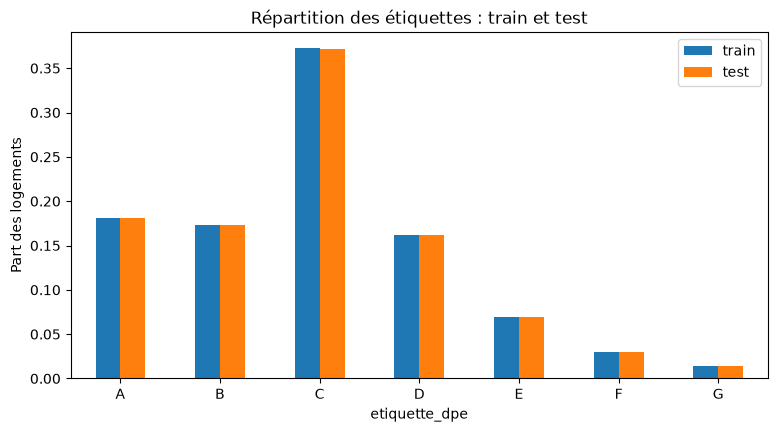

In [14]:
repartition = pd.concat(
    {"train": train[ETIQ].value_counts(normalize=True), "test": test[ETIQ].value_counts(normalize=True)},
    axis=1,
).reindex(ORDRE)
print("Part de chaque étiquette (%) :")
print((repartition * 100).round(2).to_string())
print("\nPart de chaque jeu (%) :")
print((pd.concat({"train": train["source_jeu"].value_counts(normalize=True),
                  "test": test["source_jeu"].value_counts(normalize=True)}, axis=1) * 100).round(2).to_string())

fig, ax = plt.subplots()
repartition.plot.bar(ax=ax, rot=0)
ax.set_title("Répartition des étiquettes : train et test")
ax.set_ylabel("Part des logements")
sauver(fig, "02_etiquettes_train_test")
plt.show()

On constate que qu'il y a presque les meme proportion en train et test

* Quelques information sur les bariables catégorielles et numériques dans tran et test

In [15]:
comp_num = pd.DataFrame({
    "moyenne_train": train[VAR_NUM].mean(), "moyenne_test": test[VAR_NUM].mean(),
    "mediane_train": train[VAR_NUM].median(), "mediane_test": test[VAR_NUM].median(),
})
comp_num["ecart_relatif_moyenne"] = comp_num["moyenne_test"] / comp_num["moyenne_train"] - 1
print("Variables numériques :")
display(comp_num)

lignes = []
for c in VAR_CAT:
    p = train[c].fillna("NA").value_counts(normalize=True)
    q = test[c].fillna("NA").value_counts(normalize=True)
    modalites = p.index.union(q.index)
    ecart = (p.reindex(modalites).fillna(0) - q.reindex(modalites).fillna(0)).abs()
    lignes.append({"variable": c, "modalite_principale": p.index[0], "part_train": p.iloc[0],
                   "part_test": q.get(p.index[0], 0.0), "ecart_max_points": 100 * ecart.max()})
print("Variables catégorielles (écart maximal de part entre train et test, en points de pourcentage) :")
pd.DataFrame(lignes).set_index("variable").sort_values("ecart_max_points", ascending=False)

Variables numériques :


,moyenne_train,moyenne_test,mediane_train,mediane_test,ecart_relatif_moyenne
surface_habitable_logement,79.412,79.009,67.700,68.400,-0.005
hauteur_sous_plafond,2.585,2.583,2.500,2.500,-0.001
annee_construction,"1,991.039","1,990.017","2,000.000","1,997.000",-0.001
nombre_niveau_logement,1.331,1.286,1.000,1.000,-0.034
numero_etage_appartement,0.214,0.204,0.000,0.000,-0.047
nombre_niveau_immeuble,3.678,3.420,3.000,3.000,-0.070
nombre_appartement,8.941,6.758,1.000,1.000,-0.244
surface_habitable_immeuble,"1,899.104","1,775.377","1,201.800","1,147.600",-0.065
volume_stockage_generateur_n1_ecs_n1,149.161,174.183,150.000,150.000,0.168
surface_chauffee_installation_chauffage_n1,219.108,215.909,62.650,62.400,-0.015


Variables catégorielles (écart maximal de part entre train et test, en points de pourcentage) :


C:\Users\tsali\AppData\Local\Temp\ipykernel_5524\623314553.py:11: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  p = train[c].fillna("NA").value_counts(normalize=True)
C:\Users\tsali\AppData\Local\Temp\ipykernel_5524\623314553.py:12: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  q = test[c].fillna("NA").value_counts(normalize=True)


,modalite_principale,part_train,part_test,ecart_max_points
variable,,,,
periode_construction,1948-1974,0.186,0.172,2.589
protection_solaire_exterieure,1.000,0.540,0.555,2.316
type_installation_chauffage,individuel,0.694,0.716,2.232
type_emetteur_installation_chauffage_n1,Soufflage d'air chaud (air soufflé) avec distr...,0.179,0.167,2.142
type_generateur_n1_installation_n1,PAC air/air installée à partir de 2015,0.240,0.231,2.123
type_generateur_n1_ecs_n1,Ballon électrique à accumulation vertical Caté...,0.266,0.287,2.099
type_generateur_chauffage_principal,NA,0.749,0.748,2.047
logement_traversant,oui,0.521,0.502,1.839
qualite_isolation_menuiseries,moyenne,0.436,0.435,1.829


## 5. Sélection de variables (sur le train uniquement)
On procède en trois temps : 
* 1) écarter ce qui est inutilisable
* 2) regarder le lien de chaque variable avec la consommation
* 3) mesurer l'importance des variables restantes dans une forêt aléatoire et garder celles qui portent l'essentiel.

### 5.1 Valeurs manquantes et variables quasi constantes

In [16]:
tab = pd.DataFrame(index=CANDIDATES)
tab["type"] = ["numérique" if c in VAR_NUM else "catégorielle" for c in tab.index]
tab["manquants"] = train[CANDIDATES].isna().mean()
tab["nb_modalites"] = train[CANDIDATES].nunique()
tab["part_dominante"] = [
    train[c].value_counts(normalize=True).iloc[0] if train[c].notna().any() else np.nan for c in tab.index
]
tab["trop_de_manquants"] = tab["manquants"] > SEUIL_MANQUANTS
tab["quasi_constante"] = tab["part_dominante"] >= SEUIL_PART_DOMINANTE
tab.sort_values("manquants", ascending=False)

,type,manquants,nb_modalites,part_dominante,trop_de_manquants,quasi_constante
position_logement_dans_immeuble,catégorielle,0.991,3,0.752,True,False
typologie_logement,catégorielle,0.991,5,0.891,True,False
presence_production_pv,catégorielle,0.977,2,0.593,True,False
nombre_niveau_immeuble,numérique,0.858,14,0.364,True,False
surface_habitable_immeuble,numérique,0.810,1698,0.015,True,False
type_generateur_chauffage_principal_ecs,catégorielle,0.749,68,0.310,True,False
type_generateur_chauffage_principal,catégorielle,0.749,82,0.295,True,False
type_generateur_froid,catégorielle,0.485,17,0.581,False,False
annee_construction,numérique,0.434,158,0.049,False,False
nombre_appartement,numérique,0.427,95,0.748,False,False


### 5.2 Corrélation entre variables numériques

In [17]:
corr = train[VAR_NUM].corr(method="spearman")
display(corr.round(2))

redondantes = {}
for i, a in enumerate(VAR_NUM):
    for b in VAR_NUM[i + 1:]:
        correlation = float(corr.loc[a, b])
        if abs(correlation) >= SEUIL_CORRELATION:
            # on garde la variable la mieux remplie
            perdant = a if tab.loc[a, "manquants"] > tab.loc[b, "manquants"] else b
            gagnant = b if perdant == a else a
            redondantes[perdant] = f"redondante avec {gagnant} (|Spearman| = {abs(correlation):.2f})"
print("Variables redondantes :", redondantes or "aucune")

,surface_habitable_logement,hauteur_sous_plafond,annee_construction,nombre_niveau_logement,numero_etage_appartement,nombre_niveau_immeuble,nombre_appartement,surface_habitable_immeuble,volume_stockage_generateur_n1_ecs_n1,surface_chauffee_installation_chauffage_n1
surface_habitable_logement,1.000,0.130,-0.010,0.250,-0.090,0.100,0.050,0.030,0.340,0.720
hauteur_sous_plafond,0.130,1.000,-0.280,-0.020,0.080,-0.110,-0.200,-0.160,-0.030,0.030
annee_construction,-0.010,-0.280,1.000,-0.070,-0.130,-0.740,0.240,0.060,0.290,0.000
nombre_niveau_logement,0.250,-0.020,-0.070,1.000,-0.060,-0.070,0.040,-0.090,0.150,0.140
numero_etage_appartement,-0.090,0.080,-0.130,-0.060,1.000,0.020,0.190,-0.080,-0.070,-0.090
nombre_niveau_immeuble,0.100,-0.110,-0.740,-0.070,0.020,1.000,0.240,0.320,-0.350,0.580
nombre_appartement,0.050,-0.200,0.240,0.040,0.190,0.240,1.000,0.620,-0.190,0.570
surface_habitable_immeuble,0.030,-0.160,0.060,-0.090,-0.080,0.320,0.620,1.000,-0.280,0.440
volume_stockage_generateur_n1_ecs_n1,0.340,-0.030,0.290,0.150,-0.070,-0.350,-0.190,-0.280,1.000,0.140
surface_chauffee_installation_chauffage_n1,0.720,0.030,0.000,0.140,-0.090,0.580,0.570,0.440,0.140,1.000


Variables redondantes : aucune


Constat :
- les corrélations entre les variables sont relativement faibles. La plus élevée en valeur absolue est celle entre la surface habitable et le nombre de niveaux : 0,240. Cela ne révèle donc pas de forte relation monotone entre ces variables

### 5.3 Lien avec la consommation
- **Numériques** : corrélation de Spearman avec la consommation (de -1 à 1 ; elle mesure toute relation qui va toujours dans le même sens).
- **Catégorielles** : médiane de la consommation pour chaque modalité fréquente (au moins 1 % des logements). Plus l'écart entre la plus haute et la plus basse médiane est grand, plus la variable distingue les logements.

In [18]:
ref = train.loc[~train["conso_aberrante"]]

lien_num = pd.Series({c: ref[c].corr(ref[CONSO], method="spearman") for c in VAR_NUM},
                     name="spearman_avec_consommation")
print("Variables numériques :")
display(lien_num.sort_values(key=abs, ascending=False).to_frame())

lignes = []
for c in VAR_CAT:
    part = ref[c].value_counts(normalize=True)
    frequentes = part[part >= 0.01].index
    med = ref[ref[c].isin(frequentes)].groupby(c)[CONSO].median()
    lignes.append({"variable": c, "modalites_frequentes": len(frequentes),
                   "mediane_min": med.min(), "mediane_max": med.max(),
                   "ecart_de_mediane": med.max() - med.min()})
lien_cat = pd.DataFrame(lignes).set_index("variable").sort_values("ecart_de_mediane", ascending=False)
print("Variables catégorielles (consommation en kWhEP/m²/an) :")
lien_cat

Variables numériques :


,spearman_avec_consommation
annee_construction,-0.747
nombre_niveau_immeuble,0.608
nombre_appartement,-0.315
surface_chauffee_installation_chauffage_n1,-0.226
volume_stockage_generateur_n1_ecs_n1,-0.184
hauteur_sous_plafond,0.173
surface_habitable_logement,-0.155
surface_habitable_immeuble,-0.132
nombre_niveau_logement,0.105
numero_etage_appartement,-0.034


Variables catégorielles (consommation en kWhEP/m²/an) :


,modalites_frequentes,mediane_min,mediane_max,ecart_de_mediane
variable,,,,
type_generateur_chauffage_principal,14,63.600,224.800,161.200
periode_construction,10,41.400,199.800,158.400
type_generateur_n1_installation_n1,14,68.200,222.000,153.800
type_generateur_chauffage_principal_ecs,13,41.000,187.750,146.750
type_emetteur_installation_chauffage_n1,15,81.350,218.900,137.550
type_generateur_n1_ecs_n1,13,45.100,181.800,136.700
qualite_isolation_menuiseries,4,48.000,181.500,133.500
qualite_isolation_murs,4,49.000,175.300,126.300
position_logement_dans_immeuble,3,46.200,172.000,125.800


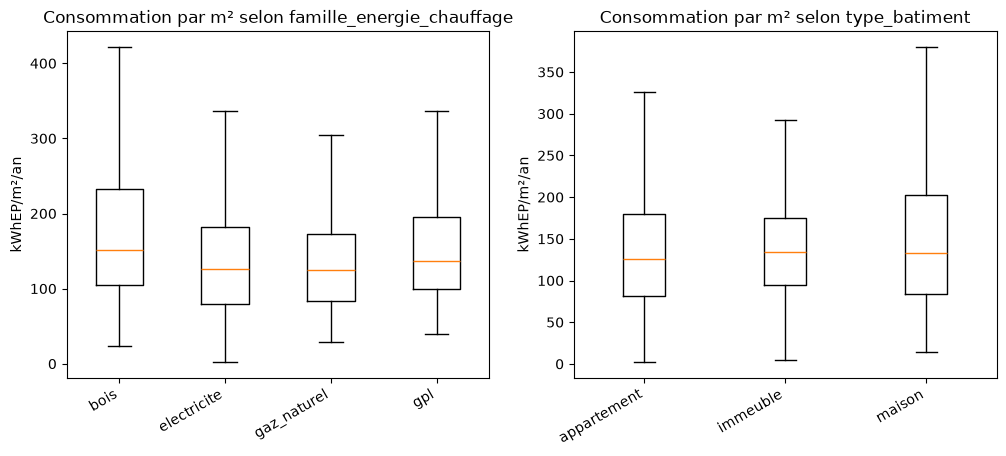

In [19]:
a_tracer = [c for c in ["famille_energie_chauffage", "type_batiment"] if c in ref.columns]
fig, axes = plt.subplots(1, len(a_tracer), figsize=(6 * len(a_tracer), 4.5))
for ax, c in zip(np.atleast_1d(axes), a_tracer):
    groupes_box = {m: g[CONSO].values for m, g in ref.groupby(c) if len(g) >= 0.01 * len(ref)}
    ax.boxplot(list(groupes_box.values()), showfliers=False)
    ax.set_xticks(range(1, len(groupes_box) + 1))
    ax.set_xticklabels(list(groupes_box.keys()), rotation=30, ha="right")
    ax.set_title(f"Consommation par m² selon {c}")
    ax.set_ylabel("kWhEP/m²/an")
sauver(fig, "02_conso_selon_modalites")
plt.show()

### 5.4 Premier tri : ce qu'on écarte avant de mesurer l'importance
Sont écartées : 
- les variables trop incomplètes, quasi constantes, redondantes
- les libellés détaillés remplacés par une famille, et les retraits décidés dans la cellule « Décisions ».
- Mesurer l'importance avant ce tri la répartirait entre des variables qui portent la même information.

In [20]:
motifs = {}
for v in CANDIDATES:
    if tab.loc[v, "trop_de_manquants"]:
        motifs[v] = f"manquants {tab.loc[v, 'manquants']:.0%}"
    elif tab.loc[v, "quasi_constante"]:
        motifs[v] = f"quasi constante ({tab.loc[v, 'part_dominante']:.1%} dans une modalité)"
for v, raison in redondantes.items():
    motifs.setdefault(v, raison)
for brute, famille in REMPLACEES.items():
    if brute in CANDIDATES and famille in CANDIDATES:
        motifs.setdefault(brute, f"libellés regroupés dans {famille}")
for v, raison in RETIRER_MANUELLEMENT.items():
    motifs.setdefault(v, raison)
for v in GARDER_MANUELLEMENT:
    motifs.pop(v, None)

candidates_filtrees = [v for v in CANDIDATES if v not in motifs]
print(f"Écartées ({len(motifs)}) :")
for v, raison in motifs.items():
    print(f"  - {v} : {raison}")
print(f"\nRestent {len(candidates_filtrees)} variables pour l'étape suivante :")
print(candidates_filtrees)

Écartées (10) :
  - nombre_niveau_immeuble : manquants 86%
  - surface_habitable_immeuble : manquants 81%
  - type_generateur_chauffage_principal : manquants 75%
  - type_generateur_chauffage_principal_ecs : manquants 75%
  - typologie_logement : manquants 99%
  - position_logement_dans_immeuble : manquants 99%
  - presence_production_pv : manquants 98%
  - type_ventilation : libellés regroupés dans famille_ventilation
  - type_energie_principale_chauffage : libellés regroupés dans famille_energie_chauffage
  - type_energie_principale_ecs : libellés regroupés dans famille_energie_ecs

Restent 32 variables pour l'étape suivante :
['surface_habitable_logement', 'hauteur_sous_plafond', 'annee_construction', 'nombre_niveau_logement', 'numero_etage_appartement', 'nombre_appartement', 'volume_stockage_generateur_n1_ecs_n1', 'surface_chauffee_installation_chauffage_n1', 'type_batiment', 'periode_construction', 'qualite_isolation_murs', 'qualite_isolation_menuiseries', 'qualite_isolation_planc

### 5.5 Importance dans une forêt aléatoire
Une forêt aléatoire est un ensemble d'arbres de décision. Elle indique, pour chaque variable, la part de la qualité du modèle qui lui est due (`feature_importances_`, la somme vaut 1). On l'estime pour les deux cibles : l'étiquette (classification) et la consommation (régression).

Précautions : ces importances sont des **repères** (la forêt favorise un peu les variables à nombreuses modalités), et elles ne prouvent pas une relation de cause à effet. Le modèle est volontairement simple, sans réglage : **un score proche de la perfection serait un signal d'alerte** (fuite de données).

In [21]:
num_f = [v for v in candidates_filtrees if v in VAR_NUM]
cat_f = [v for v in candidates_filtrees if v in VAR_CAT]


def foret(tache):
    prep = tf.construire_preprocesseur(num_f, cat_f, pour="arbres")
    if tache == "classification":
        modele = RandomForestClassifier(n_estimators=150, min_samples_leaf=3,
                                        class_weight="balanced_subsample", n_jobs=-1, random_state=GRAINE)
    else:
        modele = RandomForestRegressor(n_estimators=150, min_samples_leaf=3, n_jobs=-1, random_state=GRAINE)
    return Pipeline([("prep", prep), ("modele", modele)])


def importance_par_variable(pipeline):
    """Importance de chaque variable (les colonnes « valeur manquante » sont rattachées à leur variable)."""
    noms = pipeline.named_steps["prep"].get_feature_names_out()
    imp = pd.Series(pipeline.named_steps["modele"].feature_importances_, index=noms)
    imp.index = [n.replace("missingindicator_", "") for n in imp.index]
    return imp.groupby(level=0).sum().reindex(candidates_filtrees)


# Validation interne : un pli du train, découpé par adresse (le test n'est pas utilisé).
interne = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=GRAINE)
i_fit, i_val = next(interne.split(train, strate.loc[train.index], groups=train["groupe"]))
fit, val = train.iloc[i_fit], train.iloc[i_val]

f_cls = foret("classification").fit(fit[candidates_filtrees], fit[ETIQ])
f1_val = f1_score(val[ETIQ], f_cls.predict(val[candidates_filtrees]), average="macro")

fit_r, val_r = fit.loc[~fit["conso_aberrante"]], val.loc[~val["conso_aberrante"]]
f_reg = foret("regression").fit(fit_r[candidates_filtrees], fit_r[CONSO])
mae_val = mean_absolute_error(val_r[CONSO], f_reg.predict(val_r[candidates_filtrees]))

print(f"Validation interne (train uniquement) : F1 macro = {f1_val:.3f} | MAE = {mae_val:.1f} kWhEP/m²/an")

imp = pd.DataFrame({
    "importance_etiquette": importance_par_variable(f_cls),
    "importance_consommation": importance_par_variable(f_reg),
})
imp = imp / imp.sum()                       # chaque colonne somme à 1
imp["importance_moyenne"] = imp.mean(axis=1)
imp = imp.sort_values("importance_moyenne", ascending=False)
imp["cumul"] = imp["importance_moyenne"].cumsum()
imp

Validation interne (train uniquement) : F1 macro = 0.527 | MAE = 28.9 kWhEP/m²/an


,importance_etiquette,importance_consommation,importance_moyenne,cumul
annee_construction,0.084,0.248,0.166,0.166
surface_habitable_logement,0.080,0.127,0.104,0.270
famille_ventilation,0.046,0.109,0.078,0.347
type_generateur_froid,0.051,0.104,0.077,0.425
surface_chauffee_installation_chauffage_n1,0.078,0.043,0.061,0.485
qualite_isolation_murs,0.064,0.056,0.060,0.545
type_generateur_n1_ecs_n1,0.067,0.048,0.057,0.603
periode_construction,0.058,0.026,0.042,0.645
type_emetteur_installation_chauffage_n1,0.053,0.030,0.042,0.686
type_generateur_n1_installation_n1,0.050,0.018,0.034,0.720


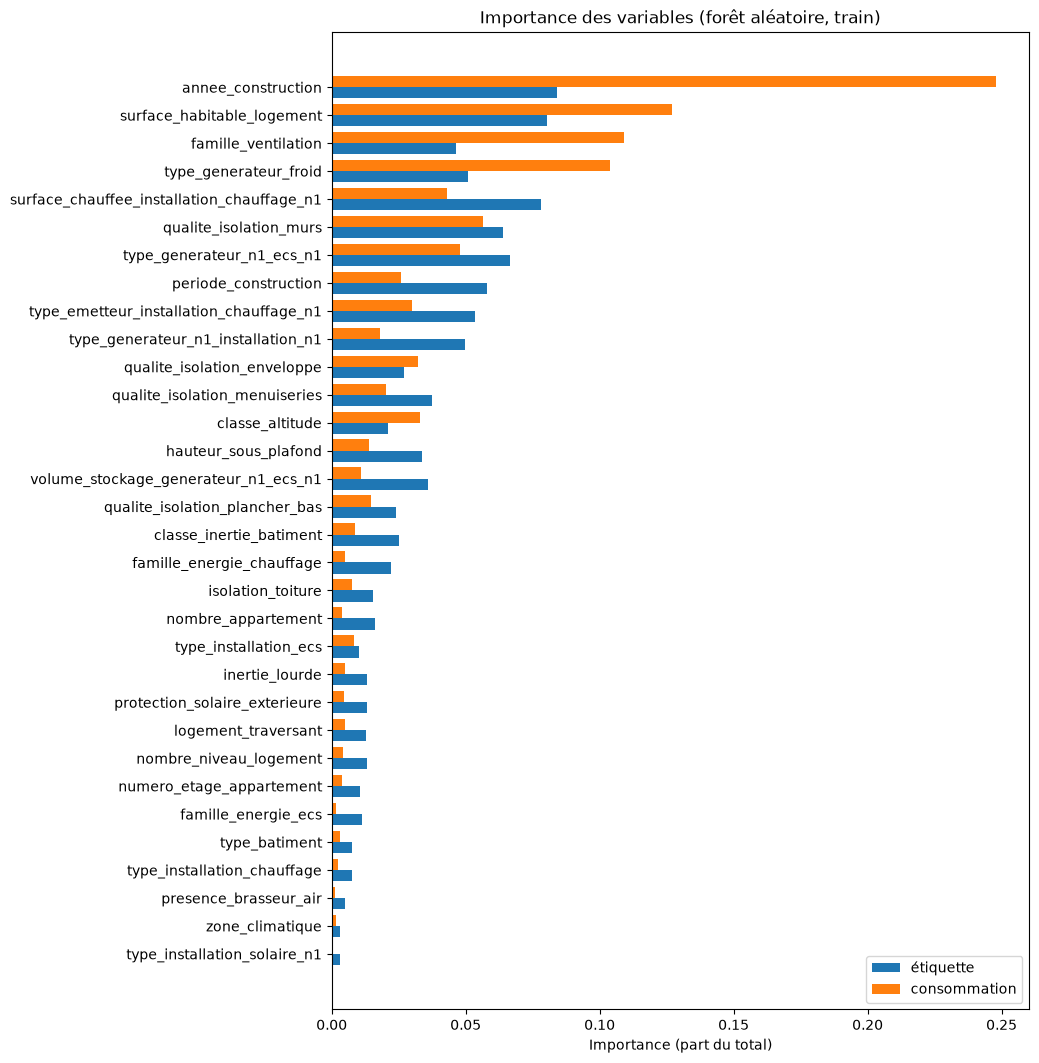

In [22]:
fig, ax = plt.subplots(figsize=(9, 0.35 * len(imp) + 1.5))
ordre_aff = imp.sort_values("importance_moyenne").index
largeur = 0.4
pos = np.arange(len(ordre_aff))
ax.barh(pos - largeur / 2, imp.loc[ordre_aff, "importance_etiquette"], largeur, label="étiquette")
ax.barh(pos + largeur / 2, imp.loc[ordre_aff, "importance_consommation"], largeur, label="consommation")
ax.set_yticks(pos)
ax.set_yticklabels(ordre_aff)
ax.set_xlabel("Importance (part du total)")
ax.set_title("Importance des variables (forêt aléatoire, train)")
ax.legend()
sauver(fig, "02_importance_variables")
plt.show()

### 5.6 Décision

In [23]:
# On garde les variables nécessaires pour atteindre PART_IMPORTANCE_CUMULEE de l'importance.
imp["retenue"] = (imp["cumul"] - imp["importance_moyenne"]) < PART_IMPORTANCE_CUMULEE
faibles = imp.index[~imp["retenue"]].tolist()
for v in faibles:
    motifs[v] = f"faible importance (hors des {PART_IMPORTANCE_CUMULEE:.0%} cumulés ; {imp.loc[v, 'importance_moyenne']:.1%})"

retenues = imp.index[imp["retenue"]].tolist()
retenues_num = [v for v in retenues if v in VAR_NUM]
retenues_cat = [v for v in retenues if v in VAR_CAT]

print(f"Variables retirées en tout ({len(motifs)}) :")
for v, raison in motifs.items():
    print(f"  - {v} : {raison}")
print(f"\nVariables retenues ({len(retenues)}) :")
print("  numériques    :", retenues_num)
print("  catégorielles :", retenues_cat)

Variables retirées en tout (19) :
  - nombre_niveau_immeuble : manquants 86%
  - surface_habitable_immeuble : manquants 81%
  - type_generateur_chauffage_principal : manquants 75%
  - type_generateur_chauffage_principal_ecs : manquants 75%
  - typologie_logement : manquants 99%
  - position_logement_dans_immeuble : manquants 99%
  - presence_production_pv : manquants 98%
  - type_ventilation : libellés regroupés dans famille_ventilation
  - type_energie_principale_chauffage : libellés regroupés dans famille_energie_chauffage
  - type_energie_principale_ecs : libellés regroupés dans famille_energie_ecs
  - logement_traversant : faible importance (hors des 95% cumulés ; 0.9%)
  - nombre_niveau_logement : faible importance (hors des 95% cumulés ; 0.9%)
  - numero_etage_appartement : faible importance (hors des 95% cumulés ; 0.7%)
  - famille_energie_ecs : faible importance (hors des 95% cumulés ; 0.7%)
  - type_batiment : faible importance (hors des 95% cumulés ; 0.5%)
  - type_installati

**À relire avant de continuer** : pour chaque variable retirée pour « faible importance », vérifier que ce retrait est cohérent avec l'analyse de la section 5.3 (par exemple une variable à fort écart de médiane mais peu importante dans la forêt mérite un second regard). Pour en conserver une, l'ajouter à `GARDER_MANUELLEMENT`, avec la raison, puis réexécuter à partir de la section 5.4. Pour en retirer une autre, l'ajouter à `RETIRER_MANUELLEMENT`.

## 6. Validation du préprocesseur
Le préprocesseur remplit les valeurs manquantes (médiane pour les nombres, « inconnu » pour le texte) et transforme le texte en nombres. Il est **ajusté sur le train**, puis seulement appliqué au test. Deux versions : « arbres » (encodage ordinal, sans standardisation) et « linéaire » (standardisation + one-hot). On vérifie qu'elles tournent, ne perdent aucune ligne et ne laissent aucune valeur manquante.

In [24]:
for mode in ["arbres", "lineaire"]:
    prep = tf.construire_preprocesseur(retenues_num, retenues_cat, pour=mode).fit(train)
    Xtr = np.asarray(prep.transform(train), dtype=float)
    Xte = np.asarray(prep.transform(test), dtype=float)
    assert Xtr.shape[0] == len(train) and Xte.shape[0] == len(test)
    assert not np.isnan(Xtr).any() and not np.isnan(Xte).any()
    print(f"{mode:9s} : {Xtr.shape[1]} colonnes en sortie, aucun manquant (train {Xtr.shape}, test {Xte.shape})")

arbres    : 29 colonnes en sortie, aucun manquant (train (39387, 29), test (9839, 29))
lineaire  : 124 colonnes en sortie, aucun manquant (train (39387, 124), test (9839, 124))


## 7. Sauvegarde

In [25]:
config.DATA_TRAITE.mkdir(parents=True, exist_ok=True)
config.DOSSIER_MODELES.mkdir(parents=True, exist_ok=True)

train.drop(columns=["groupe"]).to_csv(config.DATA_TRAITE / "train.csv", index=False)
test.drop(columns=["groupe"]).to_csv(config.DATA_TRAITE / "test.csv", index=False)

pd.concat([
    train[["numero_dpe"]].assign(jeu="train"),
    test[["numero_dpe"]].assign(jeu="test"),
]).to_csv(config.DATA_TRAITE / "split_ids.csv", index=False)

decisions = {
    "variables_numeriques": retenues_num,
    "variables_categorielles": retenues_cat,
    "variables_retirees": motifs,
    "parametres": {
        "graine": GRAINE, "taille_test": config.TAILLE_TEST,
        "dedoublonner_copies_exactes": DEDOUBLONNER_COPIES_EXACTES,
        "seuil_conso_aberrante": SEUIL_CONSO_ABERRANTE,
        "seuil_manquants": SEUIL_MANQUANTS, "seuil_part_dominante": SEUIL_PART_DOMINANTE,
        "seuil_correlation": SEUIL_CORRELATION, "part_importance_cumulee": PART_IMPORTANCE_CUMULEE,
    },
}
with open(config.DOSSIER_MODELES / "variables_retenues.json", "w", encoding="utf-8") as f:
    json.dump(decisions, f, ensure_ascii=False, indent=2)

tab.join(imp).to_csv(config.DATA_TRAITE / "selection_variables_resume.csv")
print("Fichiers écrits :")
for chemin in [config.DATA_TRAITE / "train.csv", config.DATA_TRAITE / "test.csv",
               config.DATA_TRAITE / "split_ids.csv", config.DOSSIER_MODELES / "variables_retenues.json",
               config.DATA_TRAITE / "selection_variables_resume.csv"]:
    print(" -", chemin.relative_to(config.RACINE))

Fichiers écrits :
 - data\processed\train.csv
 - data\processed\test.csv
 - data\processed\split_ids.csv
 - models\variables_retenues.json
 - data\processed\selection_variables_resume.csv
